# Figure 1

This notebook draws Figure 1. It reads the disclosure-safe tables in `data/derived/` and writes `figures/Figure1.pdf`. Review-level records are not required.

Run every cell from top to bottom. Each panel is drawn in its own cell and shown below that cell in the notebook client. Panel A opens a new canvas, so start from Panel A if you re-run later cells.

To rebuild both main-text figures in one step, without opening a notebook, run `python code/draw_figures.py` from the repository root. The script uses the same drawing code and writes identical PDFs.

## Setup

Colors, group labels, type sizes, and small drawing helpers. The next cell finds the replication-package root even when the Jupyter working directory is `code/`.

In [1]:
from __future__ import annotations

import csv
import math
from pathlib import Path

from reportlab.lib.colors import HexColor, black, white
from reportlab.pdfbase.pdfmetrics import stringWidth
from reportlab.pdfgen import canvas


starts = [Path.cwd().resolve()]
try:
    # VS Code / Cursor expose the notebook path even when cwd is code/.
    starts.insert(0, Path(__vsc_ipynb_file__).resolve().parent)
except NameError:
    pass

ROOT = None
seen = set()
for start in starts:
    for p in [start, *start.parents]:
        if str(p) in seen:
            continue
        seen.add(str(p))
        if (p / "data" / "derived").is_dir():
            ROOT = p
            break
        nested = p / "rating-comment-gaps"
        if (nested / "data" / "derived").is_dir():
            ROOT = nested
            break
    if ROOT is not None:
        break
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/derived. Open this notebook from the replication package."
    )

DATA = ROOT / "data" / "derived"
OUT = ROOT / "figures"
OUT.mkdir(parents=True, exist_ok=True)

# Final print size: 13.0 cm wide (368.5 pt), with the caption set beside the figure.
W = 368.5
H = 200.0  # drawing height; each figure's page box is cropped to its content (see Canvas)
RACE = {
    "White": HexColor("#666666"),
    "Black": HexColor("#D55E00"),
    "Hispanic": HexColor("#0072B2"),
    "Asian": HexColor("#009E73"),
}
GRID = HexColor("#D9D9D9")
LIGHT = HexColor("#A8A8A8")
TEXT = HexColor("#222222")
MID = HexColor("#777777")
INK = HexColor("#555555")
GROUPS = [
    "White_Male", "White_Female",
    "Black_Male", "Black_Female",
    "Hispanic_Male", "Hispanic_Female",
    "Asian_Male", "Asian_Female",
]
SHORT = {
    "White_Male": "White men", "White_Female": "White women",
    "Black_Male": "Black men", "Black_Female": "Black women",
    "Hispanic_Male": "Hispanic men", "Hispanic_Female": "Hispanic women",
    "Asian_Male": "Asian men", "Asian_Female": "Asian women",
}
ABBR = {
    "White_Male": "WM", "White_Female": "WW",
    "Black_Male": "BM", "Black_Female": "BW",
    "Hispanic_Male": "HM", "Hispanic_Female": "HW",
    "Asian_Male": "AM", "Asian_Female": "AW",
}
DIMS = [
    "Warmth", "Competence", "Brilliance", "Effort",
    "Complaint severity", "Positive affect", "Negative affect",
]

# Type sizes (pt): ticks, row labels, axis titles, value labels, legend, panel letters.
FT, FL, FA, FV, FG, FLET = 6.0, 6.0, 6.5, 6.0, 6.0, 8.0
MS = 2.6          # marker size
PB, PH = 48.0, 138.0  # plot bottom and plot height
GAP = 20.0        # space between panel A and panel B's row labels
LABW = max(stringWidth(SHORT[g], "Helvetica", FL) for g in GROUPS[1:])
LEG1 = PB - 30    # legend baseline


def rows(name):
    with (DATA / name).open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def xmap(v, left, width, lo, hi):
    """Map a data value onto the plot's horizontal range in page units."""
    return left + (v - lo) / (hi - lo) * width


def marker(c, x, y, color, female=False, open_marker=False, size=MS):
    """Race color; triangle = women, circle = men; open fill marks the text-predicted series."""
    c.setStrokeColor(color)
    c.setLineWidth(0.8)
    c.setFillColor(white if open_marker else color)
    if female:
        p = c.beginPath()
        p.moveTo(x, y + size)
        p.lineTo(x - size, y - size)
        p.lineTo(x + size, y - size)
        p.close()
        c.drawPath(p, fill=1, stroke=1)
    else:
        c.circle(x, y, size * 0.92, fill=1, stroke=1)


def letter(c, x, s):
    c.setFillColor(TEXT)
    c.setFont("Helvetica-Bold", FLET)
    c.drawString(x, H - 9, s)


def xaxis(c, left, width, lo, hi, ticks, label):
    """Vertical grid lines, tick labels, axis title, and a dashed line at zero."""
    c.setStrokeColor(GRID)
    c.setLineWidth(0.4)
    for t in ticks:
        x = xmap(t, left, width, lo, hi)
        c.line(x, PB, x, PB + PH)
        c.setFillColor(TEXT)
        c.setFont("Helvetica", FT)
        c.drawCentredString(x, PB - 8, f"{t:g}")
    c.setStrokeColor(TEXT)
    c.setLineWidth(0.6)
    c.line(left, PB, left + width, PB)
    c.setFont("Helvetica", FA)
    c.setFillColor(TEXT)
    c.drawCentredString(left + width / 2, PB - 17.5, label)
    c.setStrokeColor(MID)
    c.setLineWidth(0.6)
    c.setDash(1.2, 1.8)
    z = xmap(0, left, width, lo, hi)
    c.line(z, PB, z, PB + PH)
    c.setDash()


def legend_item(c, x, y, kind, text):
    """kind: 'open_pair', 'filled_pair', 'bar', or ('single', color, open)."""
    if kind == "open_pair":
        marker(c, x, y, INK, False, True)
        marker(c, x + 8, y, INK, True, True)
        tx = x + 14
    elif kind == "filled_pair":
        marker(c, x, y, INK, False, False)
        marker(c, x + 8, y, INK, True, False)
        tx = x + 14
    elif kind == "bar":
        c.saveState()
        c.setStrokeColor(INK)
        c.setLineWidth(4.5)
        c.setStrokeAlpha(0.24)
        c.line(x - 3, y, x + 11, y)
        c.restoreState()
        tx = x + 14
    else:
        _, col, op = kind
        marker(c, x, y, col, False, op)
        tx = x + 6
    c.setFillColor(TEXT)
    c.setFont("Helvetica", FG)
    c.drawString(tx, y - 2, text)
    return tx + stringWidth(text, "Helvetica", FG)


def legend_row(c, items, right, y, gap=6):
    """One-line legend whose last label ends at x = right (the panel's right edge)."""
    width = sum((14 if k in ("open_pair", "filled_pair", "bar") else 6)
                + stringWidth(t, "Helvetica", FG) + 3 for k, t in items) + gap * (len(items) - 1)
    x = right - width + 3
    for kind, text in items:
        x = legend_item(c, x, y, kind, text) + gap + 3


def decomp_panel(c, values, left, width, lo, hi, ticks, xlabel, fmt):
    """Observed gap (filled), gap predicted from the review's text (open), and their difference (bar)."""
    xaxis(c, left, width, lo, hi, ticks, xlabel)
    order = list(reversed(GROUPS[1:]))
    dy = PH / len(order)
    for i, g in enumerate(order):
        y = PB + (i + 0.5) * dy
        obs, ose, pred, plo, phi = values[g]
        col, fem = RACE[g.split("_")[0]], g.endswith("Female")
        X = lambda v: xmap(v, left, width, lo, hi)
        c.setFillColor(TEXT)
        c.setFont("Helvetica", FL)
        c.drawRightString(left - 3, y - 2, SHORT[g])
        c.saveState()
        c.setStrokeColor(col)
        c.setLineWidth(4.5)
        c.setStrokeAlpha(0.24)
        c.line(X(pred), y, X(obs), y)
        c.restoreState()
        c.saveState()
        c.setStrokeColor(col)
        c.setLineWidth(0.55)
        c.setStrokeAlpha(0.45)
        c.line(X(plo), y, X(phi), y)
        c.restoreState()
        c.setStrokeColor(col)
        c.setLineWidth(0.7)
        c.line(X(obs - 1.96 * ose), y, X(obs + 1.96 * ose), y)
        marker(c, X(pred), y, col, fem, True)
        marker(c, X(obs), y, col, fem, False)
        c.setFillColor(col)
        c.setFont("Helvetica", FV)
        label = fmt(obs - pred)
        if abs(X(pred) - X(obs)) >= stringWidth(label, "Helvetica", FV) + 2:
            c.drawCentredString((X(pred) + X(obs)) / 2, y + 4.6, label)
        else:  # bar shorter than its label: place the label left of the observed interval
            c.drawRightString(min(X(obs - 1.96 * ose), X(plo), X(pred), X(obs)) - 2.5, y - 2, label)
    legend_row(c, [("open_pair", "Predicted from text"), ("filled_pair", "Observed"),
                   ("bar", "Difference")], left + width, LEG1)


def new_canvas(path, y0, y1, title):
    """Page box cropped to the figure content: the page spans drawing heights y0 to y1."""
    c = canvas.Canvas(str(path), pagesize=(W, y1 - y0), pageCompression=1)
    c.setTitle(title)
    c.translate(0, -y0)
    return c


def show_canvas(c, zoom=3.0):
    """Display the current page in the notebook without closing the drawing canvas."""
    from io import BytesIO

    from IPython.display import Image, clear_output, display
    import fitz

    preview = canvas.Canvas(BytesIO(), pagesize=c._pagesize, pageCompression=1)
    preview._code = list(c._code)
    preview._preamble = c._preamble
    preview._extgstate = c._extgstate
    preview._currentPageHasImages = c._currentPageHasImages
    page = fitz.open(stream=preview.getpdfdata(), filetype="pdf")[0]
    pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
    clear_output(wait=True)
    display(Image(data=pix.tobytes("png"), format="png"))


def show_pdf(path, zoom=3.0):
    """Display a saved PDF page in the notebook."""
    from IPython.display import Image, clear_output, display
    import fitz

    page = fitz.open(path)[0]
    pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
    clear_output(wait=True)
    display(Image(data=pix.tobytes("png"), format="png"))

## Data

Figure 1 is drawn from two disclosure-safe files in `data/derived/`:

- `figure1_a.csv`: one-at-a-time and joint associations between the seven text measures and the star rating
- `figure1_b.csv`: observed star-rating gaps, gaps predicted from the review's text, and their difference

In [2]:
a = [r for r in rows("figure1_a.csv") if r["outcome"] == "Star rating"]
b = {r["group"]: r for r in rows("figure1_b.csv")}

## Canvas

Page size and output path. The figure is 13.0 cm (368.5 pt) wide; the page box keeps the drawn content plus a 3-pt margin. The Panel A cell recreates this canvas so that re-running the figure starts from a clean page.

In [3]:
FIG1_PAGE = (11.75, 199.75)  # drawing heights kept on the page (content plus 3 pt)
c = new_canvas(OUT / "Figure1.pdf", *FIG1_PAGE, "Figure 1. Star ratings carry larger demographic gaps than the accompanying comments imply")

## Panel A

Standardized associations of the seven text measures with the star rating, estimated one at a time (open gray markers) and jointly with race-by-gender indicators (filled black markers). The joint coefficients are the weights used to predict ratings from text in Panel B. The 95% confidence intervals are drawn but are narrower than the markers.

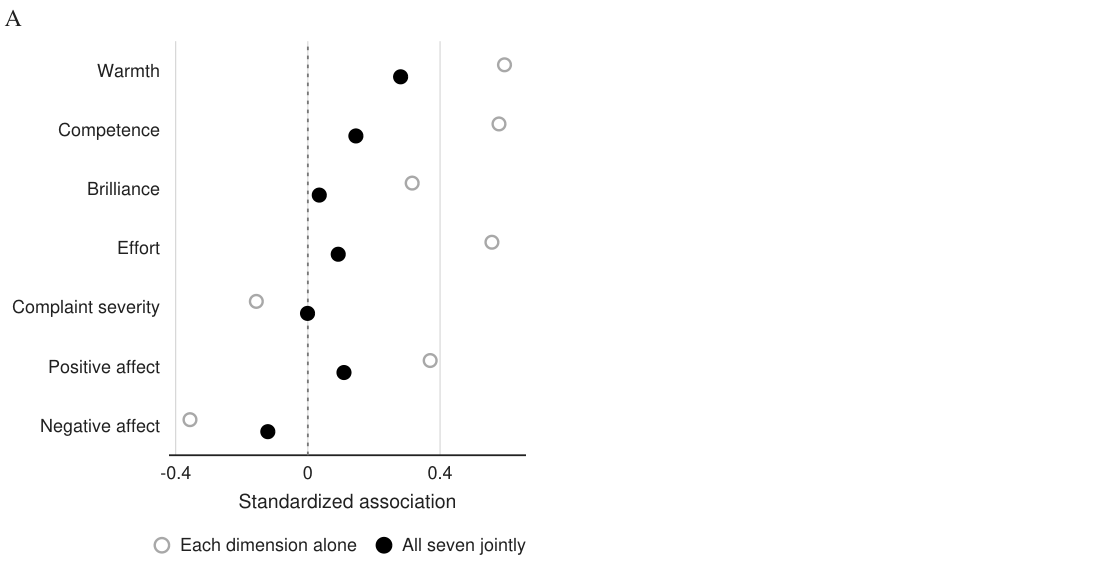

In [4]:
# Recreate the canvas so re-running this cell starts a clean page.
c = new_canvas(OUT / "Figure1.pdf", *FIG1_PAGE, "Figure 1. Star ratings carry larger demographic gaps than the accompanying comments imply")

dimw = max(stringWidth(d, "Helvetica", FL) for d in DIMS)
leftA, widthA = 4 + dimw + 3, 119.0
lo, hi = -0.42, 0.66
letter(c, 1.5, "A")
xaxis(c, leftA, widthA, lo, hi, [-0.4, 0, 0.4], "Standardized association")
dy = PH / len(DIMS)
for i, dim in enumerate(reversed(DIMS)):
    y = PB + (i + 0.5) * dy
    c.setFillColor(TEXT)
    c.setFont("Helvetica", FL)
    c.drawRightString(leftA - 3, y - 2, dim)
    for spec, offset, color, open_m in [
        ("Marginal (each alone)", 2.0, LIGHT, True),
        ("Joint (all seven)", -2.0, black, False),
    ]:
        r = next(x for x in a if x["dimension"] == dim and x["specification"] == spec)
        c.setStrokeColor(color)
        c.setLineWidth(0.6)
        c.line(xmap(float(r["lower"]), leftA, widthA, lo, hi), y + offset,
               xmap(float(r["upper"]), leftA, widthA, lo, hi), y + offset)
        marker(c, xmap(float(r["estimate"]), leftA, widthA, lo, hi), y + offset, color, False, open_m, 2.3)
legend_row(c, [(("single", LIGHT, True), "Each dimension alone"),
               (("single", black, False), "All seven jointly")], leftA + widthA, LEG1)

show_canvas(c)

## Panel B

Observed adjusted star-rating gaps relative to White men (filled markers) and gaps predicted from the review's text with the joint weights in Panel A (open markers). Shaded bars and labels show the difference, in SD units. Circles are men and triangles are women; color is inferred race or ethnicity.

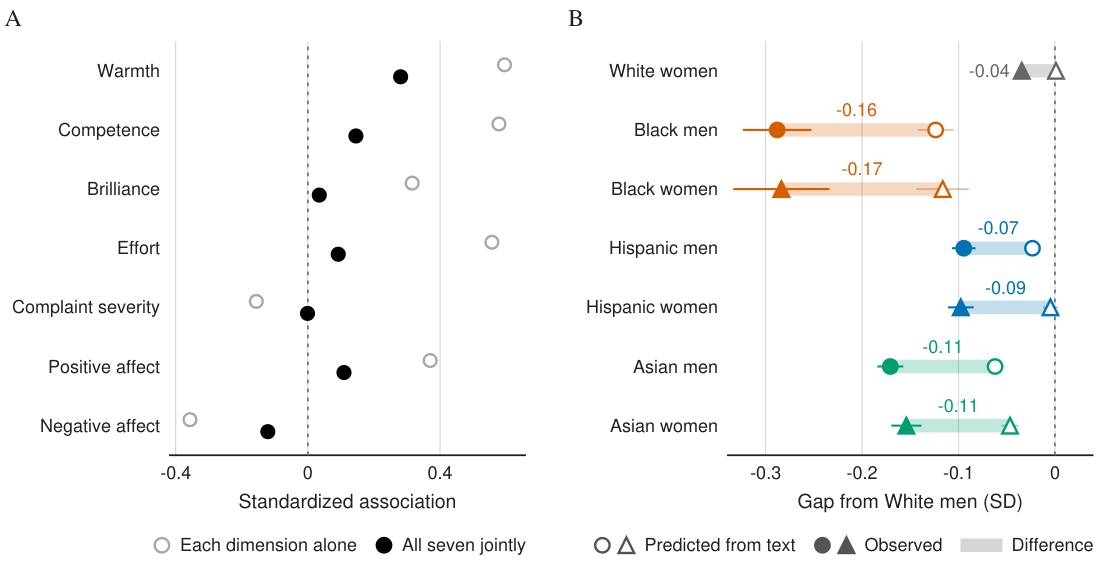

In [5]:
rA = leftA + widthA
leftB = rA + GAP + LABW + 3
widthB = W - 4 - leftB
letter(c, rA + GAP - 6, "B")
values = {
    g: (float(b[g]["observed"]), float(b[g]["observed_se"]), float(b[g]["text_predicted"]),
        float(b[g]["text_predicted_lower"]), float(b[g]["text_predicted_upper"]))
    for g in GROUPS[1:]
}
decomp_panel(c, values, leftB, widthB, -0.34, 0.04, [-0.3, -0.2, -0.1, 0],
             "Gap from White men (SD)", lambda v: f"{v:+.2f}".replace("+", ""))

show_canvas(c)

## Save

Write the vector figure to `figures/Figure1.pdf`.

figures/Figure1.pdf


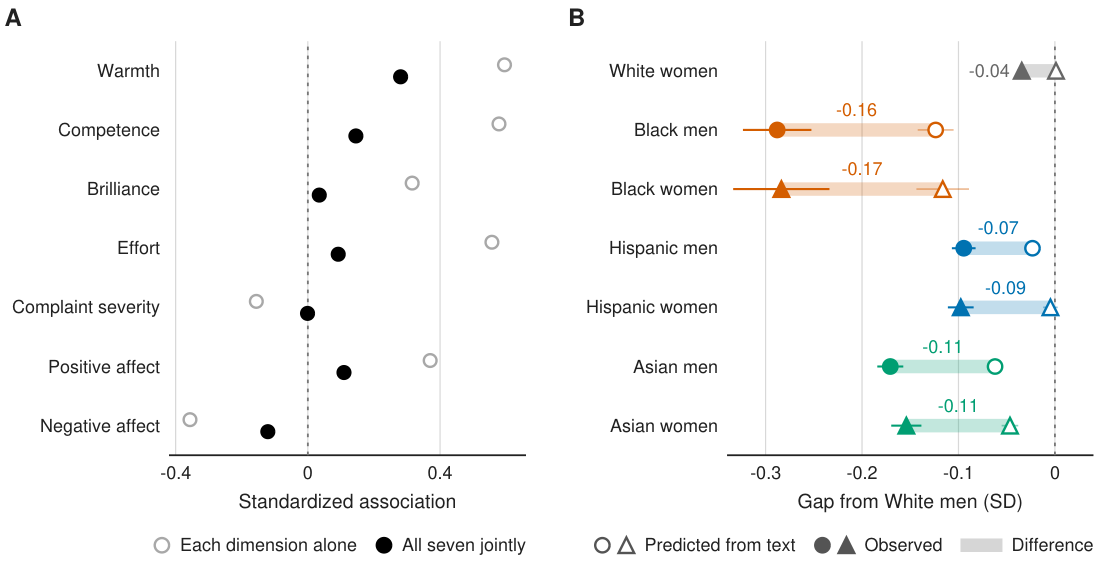

In [6]:
c.showPage()
c.save()
print((OUT / "Figure1.pdf").relative_to(ROOT))
show_pdf(OUT / "Figure1.pdf")